In [1]:
%load_ext autoreload
%autoreload 2

In [2]:

import os
import torch.backends.cudnn as cudnn
import torch
import torchvision
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time
from datetime import datetime 
import pdb
import yaml
import sys
import glob
import shutil
import tqdm
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import seaborn as sns
from scipy.stats import ttest_ind, spearmanr

sys.path.append('../../MARS')


In [4]:
pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/val_df.csv').columns

Index(['filepath', 'filename', 'filename_header', 'fullfile', 'patient_age',
       'patient_sex', 'patient_weight', 'smoking_status', 'accession',
       'study_uid', 'series_uid', 'scan_time', 'modality', 'matrix_size_1',
       'matrix_size_2', 'matrix_size_3', 'pixel_size_1', 'pixel_size_2',
       'pixel_size_3', 'pixel_size_3_str', 'slice_thickness',
       'description_series', 'description_study', 'admitting_diagnoses',
       'protocol_name', 'image_comments', 'body_part', 'manufacturer',
       'manufacturer_model', 'software', 'convolution_kernel',
       'factor_bqml2suv', 'xray_tube_current', 'kvp', 'contrast_agent',
       'patient_position', 'imaging_plane', 'image_orientation',
       'patient_history', 'img_max', 'img_min', 'img_mean', 'img_std',
       'img_sum', 'img_count_nonzeros', 'img_mean_nonzeros',
       'img_std_nonzeros', 'img_sum_nonzeros', 'reconstruction', 'corrections',
       'pixel_unit', 'frame_duration', 'tracer', 'tracer_injection_time',
       'tra

In [5]:
pred_df = pd.read_csv('/gpfs/data/mayerhoeferlab/projects/myeloma/results/2D_all_seeds_prediction/val/pred_val_mipview_aggregate.csv')

pred_df = pred_df.iloc[:, :64]
pred_df['error'] = pred_df['PET_jco'] - pred_df['probs_mean']
pred_df['error_abs'] = np.abs(pred_df['error'])

In [8]:
pred_df['patient_age'] = pred_df['patient_age'].apply(lambda x: int(x.split('Y')[0]) if isinstance(x, str) else x)
# one-hot encode stuff
pred_df = pd.get_dummies(pred_df, columns=['patient_sex', 'description_series', 'admitting_diagnoses', 'protocol_name', 'body_part', 'manufacturer',
                                 'manufacturer_model', 'software', 'patient_position', 'reconstruction',
                                 'corrections', ], drop_first=True)

In [9]:
# extract float from string
# replace All-pass with 0.00
pred_df['convolution_kernel'] = pred_df['convolution_kernel'].replace('All-pass', '0.00')
pred_df['convolution_kernel'] = pred_df['convolution_kernel'].str.extract('(\d+.\d+)').astype(float)

In [22]:
# convert injection time from float to some time object that can be added or subtracted from acquisition time
def hhmmss_to_seconds(t):
    t = int(t)
    h = int(t // 10000)
    m = int((t % 10000) // 100)
    s = t % 100
    return h * 3600 + m * 60 + s

pred_df['tracer_injection_time_seconds'] = pred_df['tracer_injection_time'].apply(hhmmss_to_seconds)
pred_df['scan_time_seconds'] = pred_df['scan_time'].apply(hhmmss_to_seconds)
pred_df['uptake_time_seconds'] = pred_df['scan_time_seconds'] - pred_df['tracer_injection_time_seconds']

In [183]:
feature_cols = [col for col in pred_df.columns if col not in ['filepath', 'filename', 'filename_header', 'fullfile', 'study_uid', 'series_uid', 'accession', 'smoking_status', 
                                                              'modality', 'pixel_size_3_str', 'description_study', 'image_comments',
                                                              'xray_tube_current', 'kvp', 'contrast_agent', 'imaging_plane',
                                                              'image_orientation', 'patient_history', 'pixel_unit', 'tracer',
                                                              'image_filter', 'contrast_route', 'img_min',
                                                              'PET_jco', 'PET_imwg', 'model_number',
                                                              'probs_mean', 'probs_max',
                                                              'error', 'error_abs', 'PET_jco']]

In [184]:
error_type = 'error_abs'
#error_type = 'error'

for col in feature_cols:
    if pred_df[col].dtype == bool:
        # compute if there is significant difference in error between True and False
        true_errors = pred_df[pred_df[col] == True][error_type]
        false_errors = pred_df[pred_df[col] == False][error_type]
        t_stat, p_val = ttest_ind(true_errors, false_errors, equal_var=False)
        if min(true_errors.count(), false_errors.count()) < 5:
            # too few samples to make any conclusion
            continue
        if p_val < 0.2:
            print(f'Column: {col}, True mean error: {true_errors.mean():.4f} (n={true_errors.count()}), False mean error: {false_errors.mean():.4f} (n={false_errors.count()}), p-value: {p_val:.4f}')
    elif np.issubdtype(pred_df[col].dtype, np.number):
        # compute correlation between value and absolute error
        corr, p_val = spearmanr(pred_df[col], pred_df[error_type], nan_policy='omit')
        if (~pred_df[col].isna()).sum() < 5:
            # too few samples to make any conclusion
            continue
        if p_val < 0.2:
            print(f'{col} {corr:.2f} {p_val:.4f}')
        #if abs(corr) > 0.2:
        #    print(f'Column: {col}, correlation with absolute error: {corr:.4f}')
    else:
        print(col)
        assert False

matrix_size_1 0.18 0.0297
matrix_size_2 0.18 0.0297
convolution_kernel -0.15 0.0784
img_max 0.15 0.0673
img_mean -0.13 0.1153
img_count_nonzeros 0.13 0.1085
frame_duration -0.17 0.0401
Column: description_series_PET WB Corrected, True mean error: 0.2692 (n=64), False mean error: 0.1890 (n=84), p-value: 0.1117
Column: description_series_PET WB _Corrected (AC), True mean error: 0.0818 (n=13), False mean error: 0.2373 (n=135), p-value: 0.0161
Column: protocol_name_1a_PETCT_WB_FDG, True mean error: 0.1042 (n=10), False mean error: 0.2323 (n=138), p-value: 0.1023
Column: manufacturer_model_1080, True mean error: 0.1367 (n=40), False mean error: 0.2558 (n=108), p-value: 0.0172
Column: manufacturer_model_Biograph 40_mCT, True mean error: 0.6133 (n=7), False mean error: 0.2043 (n=141), p-value: 0.0514
Column: software_PET/CT 2010A, True mean error: 0.1206 (n=23), False mean error: 0.2426 (n=125), p-value: 0.0397
Column: reconstruction_OSEM2D 2i21s, True mean error: 0.1191 (n=20), False mean er

In [185]:
def plot_against_col(col, error_type, binarize_continuous = False):
    tmp = pred_df.copy()
    if binarize_continuous and np.issubdtype(pred_df[col].dtype, np.number):
        median_val = pred_df[col].median()
        tmp[col] = pred_df[col] > median_val
        print(f'Binarized {col} at median value {median_val}')

    # use seaborn scatter
    if np.issubdtype(tmp[col].dtype, np.number):
        plt.figure(figsize=(6, 6))
        sns.scatterplot(data=tmp, x=col, y=error_type)
        plt.xlabel(col)
        plt.ylabel(error_type)
        plt.title(f'{col} vs {error_type}')
        plt.show()
    else:
        # boxplot using seaborn
        plt.figure(figsize=(8, 6))
        sns.boxplot(data=tmp, x=col, y=error_type)
        plt.xlabel(col)
        plt.ylabel(error_type)
        plt.title(f'{col} vs {error_type}')
        plt.xticks(rotation=45, ha='right')
        # on the xtick label, list the number of samples in each category
        counts = tmp[col].value_counts()
        
        #plt.gca().set_xticklabels(new_labels)
        old_labels = [item.get_text() for item in plt.gca().get_xticklabels()]
        new_labels = [f'{label}\n(n={counts[label == "True"]})' for label
                        in old_labels]
        print(bool('True'))
        plt.gca().set_xticklabels(new_labels)
        plt.show()


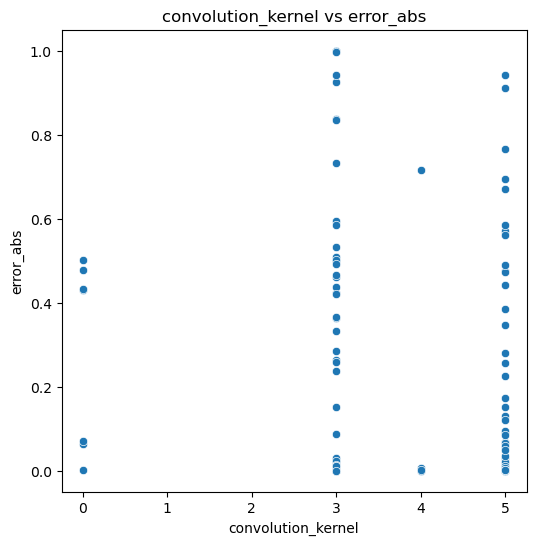

In [ ]:
plot_against_col('convolution_kernel', 'error_abs')

In [ ]:
for col in feature_cols:
    # remove if the majority class has almost all the values
    if pred_df[col].dtype == bool:
        if pred_df[col].value_counts(normalize=True).max() > 0.95:
            print(f'Skipping {col} due to low variability')
            continue
        plot_against_col(col, 'error_abs')
    elif np.issubdtype(pred_df[col].dtype, np.number):
        if pred_df[col].nunique() < 3:
            print(f'Skipping {col} due to low variability')
            continue
        plot_against_col(col, 'error_abs', binarize_continuous=True)


In [ ]:
# perform multivariable regression of error_abs against all features
import statsmodels.api as sm
X = np.asarray(pred_df[feature_cols])
X[X == 'True'] = 1
X[X == 'False'] = 0
X = X.astype(float)
y = np.asarray(pred_df['error_abs'])
X = sm.add_constant(X)  # add constant term
model = sm.OLS(y, X, missing='drop').fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.569
Model:                            OLS   Adj. R-squared:                  0.096
Method:                 Least Squares   F-statistic:                     1.204
Date:                Fri, 10 Oct 2025   Prob (F-statistic):              0.232
Time:                        18:21:01   Log-Likelihood:                 27.082
No. Observations:                 129   AIC:                             81.84
Df Residuals:                      61   BIC:                             276.3
Df Model:                          67                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0022      0.002     -0.899      0.3